# Notebook 3 - Cleaning and customer feature engineering

> **Mentor briefing** - the seven questions we answer for every phase.

| Question | Answer |
|---|---|
| **1. What are we doing?** | Show what the cleaning step changed, then turn ~1 million transaction lines into ONE ROW PER CUSTOMER (RFM + behaviour features). |
| **2. Why?** | Segmentation and prediction models need a table with one row per customer. Raw data has one row per product line. |
| **3. Real-world problem it solves** | 'Who are our best customers and who is about to leave?' needs a number for each customer: how recently, how often, how much they buy. |
| **4. What does the code do?** | `clean_transactions` (before/after report) then `build_customer_features` aggregates with `groupby` at a **snapshot date**, using only earlier data. |
| **5. Expected output** | A table of ~5,900 customers x 14 features; a proof that features never look past the snapshot date. |
| **6. What can go wrong?** | **Data leakage**: accidentally using information from after the prediction moment. It produces beautiful metrics that collapse in production. |
| **7. How do professionals approach this?** | They define the observation window and snapshot date explicitly, build features through one function, and unit-test it for leakage (see `tests/test_features.py`). |


In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))                      # lets us import our own code from src/
from src.utils.config import get_paths, RANDOM_STATE
paths = get_paths(ROOT)

sns.set_theme(style="whitegrid", context="notebook", palette=["#2563eb", "#0d9488", "#4f46e5", "#eda100", "#eb6834", "#e87ba4"])
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "figure.figsize": (9, 4.2)})
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.width = 140
from src.features.customer_features import build_customer_features, FEATURE_COLUMNS, validate_features
from src.features.rfm import compute_rfm, add_rfm_scores, default_snapshot
clean = pd.read_parquet(paths.processed / "cleaned_transactions.parquet")
report = json.loads((paths.processed / "cleaning_report.json").read_text())

## Part A - Cleaning: before and after

In [2]:
steps = pd.DataFrame(report["steps"])
steps["rows_removed"] = steps["rows_removed"].map("{:,}".format)
display(steps[["step", "rows_removed", "note"]])
b, a = report["before"], report["after"]
print(f"rows: {report['summary']['rows_before']:,} -> {report['summary']['rows_after']:,}")

,step,rows_removed,note
0,drop unparsable date/quantity/price,0,Rows whose core fields cannot be parsed are un...
1,remove exact duplicates,"34,335","Identical rows are double-entries, not double ..."
2,remove service stock codes,"5,818",POST/Discount/Manual/Bank charges are not prod...
3,remove zero quantity,0,A line with no units carries no information.
4,remove zero/negative price,"5,964",Free items and stock adjustments are not sales.
5,remove data-entry outliers,13,|Quantity| >= 10000 or UnitPrice >= 5000; the ...
6,remove contradictory cancellations,0,Cancellation invoices with positive quantity.
7,remove unexplained negatives,0,Negative quantity without a cancellation invoi...
8,drop products with no description anywhere,0,Cannot be used by the content-based recommender.


rows: 1,067,371 -> 1,021,241


In [3]:
s = report["summary"]
pd.Series({"Gross sales (GBP)": s["gross_sales"], "Returns (GBP)": s["returns_value"], "NET revenue (GBP)": s["net_revenue"],
           "Return rate (% of gross)": s["return_rate_pct"], "Guest rows (%)": s["guest_row_pct"], "Guest revenue (%)": s["guest_revenue_pct"],
           "Flagged outlier lines": s["flagged_outlier_rows"]}).to_frame("value")

,value
Gross sales (GBP),"19,381,178.82"
Returns (GBP),"-470,772.77"
NET revenue (GBP),"18,910,406.05"
Return rate (% of gross),2.43
Guest rows (%),22.24
Guest revenue (%),13.58
Flagged outlier lines,"1,002.00"


### How returns are treated (the key design decision)
* `RecordType = "sale"` - positive quantity. `RecordType = "return"` - cancellation invoice (`C...`) with negative quantity.
* `Revenue = Quantity x UnitPrice` is therefore **negative for returns**.
* **Net revenue = sum of Revenue.** **Frequency counts only sale invoices** (a return is not a purchase).

Quick proof with one real customer who returned goods:

In [4]:
has_ret = clean[(clean.RecordType == "return") & clean.HasCustomer]["CustomerID"].value_counts().index[0]
c = clean[clean.CustomerID == has_ret]
print("customer", has_ret)
print(c.groupby("RecordType")["Revenue"].agg(["count", "sum"]))
print("NET spend =", round(c["Revenue"].sum(), 2))

customer 14911
            count        sum
RecordType                  
return        343 -13,730.36
sale        10909 272,252.79
NET spend = 258522.43


## Part B - Feature engineering

**Feature engineering** = inventing informative columns from raw data. **Aggregation** with `groupby` collapses many rows into one per group:

```python
sales.groupby("CustomerID")["InvoiceNo"].nunique()   # frequency: distinct orders per customer
```

### RFM - the classic customer triple
| Letter | Meaning | Good is... |
|---|---|---|
| **R**ecency | days since last purchase | small |
| **F**requency | number of distinct orders | large |
| **M**onetary | net spend (sales - returns) | large |

### Observation window and snapshot date (documented)
* **Observation window:** all transactions *before* the snapshot date.
* **Snapshot date:** for the final customer table, the day after the last transaction in the data. For the prediction model, earlier cut-off dates are used (Notebook 5).
* **Leakage guard:** `history_before()` keeps only rows with `InvoiceDate < snapshot_date` (strictly before).

In [5]:
snapshot = default_snapshot(clean)
print("snapshot date:", snapshot.date())
feats = build_customer_features(clean, snapshot)
assert validate_features(feats) == []
print(f"{len(feats):,} customers x {len(FEATURE_COLUMNS)} features")
feats.head()

snapshot date: 2011-12-10


5,852 customers x 14 features


,recency_days,frequency,monetary,avg_order_value,total_items,product_diversity,active_months,avg_basket_size,spend_30d,spend_60d,spend_90d,avg_days_between_purchases,tenure_days,return_rate,country,snapshot_date
CustomerID,,,,,,,,,,,,,,,,
12346,529,2,169.36,84.68,24.00,24,2,12.00,0.00,0.00,0.00,118.03,647,0.00,United Kingdom,2011-12-10
12347,2,8,"4,921.53",615.19,"2,967.00",126,8,27.75,224.82,"1,519.14","1,519.14",57.44,404,0.00,Iceland,2011-12-10
12348,75,5,"1,658.40",331.68,"2,704.00",24,5,8.40,0.00,0.00,270.00,90.73,438,0.00,Finland,2011-12-10
12349,18,3,"3,654.54","1,226.23","1,621.00",137,3,57.33,"1,457.55","1,457.55","1,457.55",285.43,589,0.01,Italy,2011-12-10
12350,310,1,294.40,294.40,196.00,16,1,16.00,0.00,0.00,0.00,NaN,310,0.00,Norway,2011-12-10


| Feature | Meaning |
|---|---|
| `recency_days`, `frequency`, `monetary` | RFM |
| `avg_order_value` | gross spend per order (GBP) |
| `total_items` | units bought |
| `product_diversity` | distinct products bought |
| `active_months` | distinct calendar months with a purchase |
| `avg_basket_size` | distinct products per order |
| `spend_30d / 60d / 90d` | net spend in the last 30/60/90 days before the snapshot |
| `avg_days_between_purchases` | mean gap between orders (undefined = NaN for one-time buyers) |
| `tenure_days` | days since first purchase |
| `return_rate` | returned value / gross sales |

### Verify by hand (rule: validate every transformation)

In [6]:
cid = int(feats.index[100])
mine = clean[(clean.CustomerID == cid) & (clean.RecordType == "sale") & (clean.InvoiceDate < snapshot)]
print("customer", cid)
print("frequency by hand:", mine.InvoiceNo.nunique(), "| table:", feats.loc[cid, "frequency"])
print("recency   by hand:", (snapshot - mine.InvoiceDate.max()).days, "| table:", feats.loc[cid, "recency_days"])
assert mine.InvoiceNo.nunique() == feats.loc[cid, "frequency"] and (snapshot - mine.InvoiceDate.max()).days == feats.loc[cid, "recency_days"]
saved = pd.read_parquet(paths.processed / "customer_features.parquet")
pd.testing.assert_frame_equal(feats, saved); print("identical to data/processed/customer_features.parquet")

customer 12448
frequency by hand: 1 | table: 1
recency   by hand: 44 | table: 44
identical to data/processed/customer_features.parquet


## Part C - Leakage: see it, then see it prevented
We pretend today is **13 June 2011** and build features. Then we delete every later transaction and rebuild. A leak-free function must return *identical* numbers.

In [7]:
cutoff = pd.Timestamp("2011-06-13")
f_full = build_customer_features(clean, cutoff)
f_past = build_customer_features(clean[clean.InvoiceDate < cutoff], cutoff)
pd.testing.assert_frame_equal(f_full, f_past)
print("OK - identical. Features at", cutoff.date(), "use only the past.")
print(f"customers known on that day: {len(f_full):,}  (vs {len(feats):,} at the end)")
both = f_full[["recency_days", "frequency", "monetary"]].join(feats[["recency_days", "frequency", "monetary"]], rsuffix="_end", how="inner").head(3)
both

OK - identical. Features at 2011-06-13 use only the past.
customers known on that day: 4,952  (vs 5,852 at the end)


,recency_days,frequency,monetary,recency_days_end,frequency_end,monetary_end
CustomerID,,,,,,
12346,349,2,169.36,529,2,169.36
12347,3,5,"2,817.48",2,8,"4,921.53"
12348,68,4,"1,388.40",75,5,"1,658.40"


The same customer looks very different on different days - that is exactly what makes a **future-looking label** possible in Notebook 5.

## Part D - RFM scores and distributions

            recency_days  frequency  monetary  R_score  F_score  M_score RFM_score
CustomerID                                                                        
12346                529          2    169.36        1        2        1       121
12347                  2          8  4,921.53        5        4        5       545
12348                 75          5  1,658.40        3        4        4       344


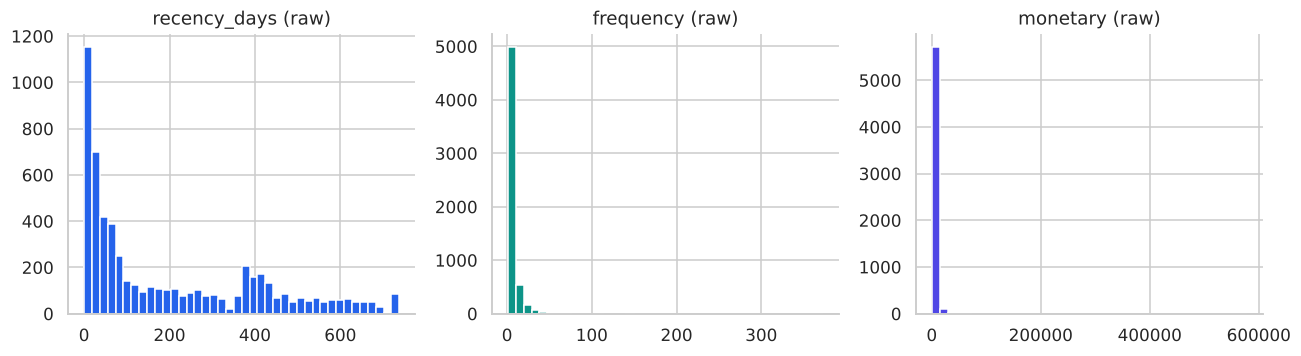

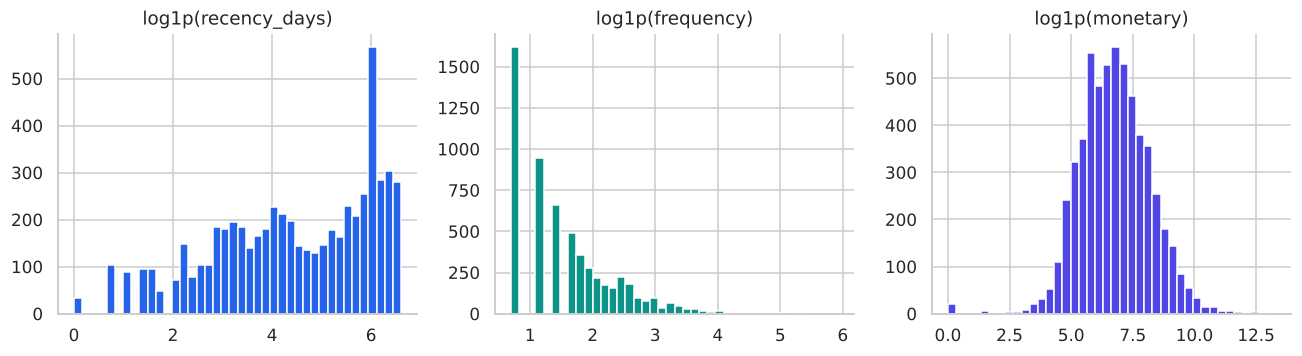

In [8]:
scored = add_rfm_scores(compute_rfm(clean, snapshot))
print(scored.head(3))
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for a, col, c in zip(ax, ["recency_days", "frequency", "monetary"], ["#2563eb", "#0d9488", "#4f46e5"]):
    a.hist(feats[col].clip(lower=0), bins=40, color=c); a.set_title(col + " (raw)")
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for a, col, c in zip(ax, ["recency_days", "frequency", "monetary"], ["#2563eb", "#0d9488", "#4f46e5"]):
    a.hist(np.log1p(feats[col].clip(lower=0)), bins=40, color=c); a.set_title("log1p(" + col + ")")
plt.tight_layout(); plt.show()

**RFM scores** rank each customer 1-5 on each letter (5 = best). `555` = best customer. They are a simple, explainable baseline; K-Means in Notebook 4 finds groups without hand-written rules.

The **log transform** turns the long right tail into a roughly bell-shaped curve - the shape K-Means handles well.

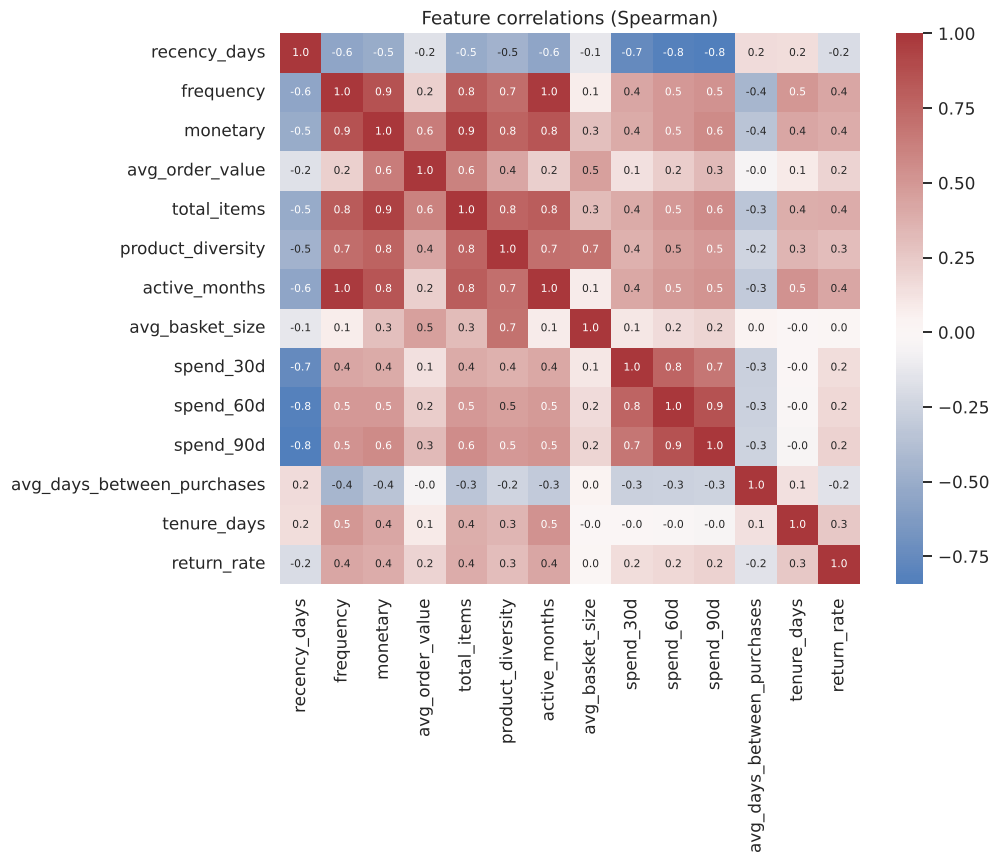

In [9]:
corr = feats[FEATURE_COLUMNS].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 6.5)); sns.heatmap(corr, cmap="vlag", center=0, annot=True, fmt=".1f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Feature correlations (Spearman)"); plt.show()

Many features are strongly correlated (`frequency`, `total_items`, `monetary`). For **K-Means** we therefore use only R, F and M (no double counting). **Tree models** and **XGBoost** cope with correlated features, and the others use regularisation.

## Check yourself
1. Why is `<` (strictly before) used instead of `<=` for the snapshot?
2. Why does `avg_days_between_purchases` have missing values, and who fills them?
3. What would go wrong if `monetary` were computed from *all* data but the label from the next 90 days?